# 9 · Performance: where returns come from, how long they last, who grows fast and how productive firms are
Four questions on the full panel (52,792 non-financial firms, 123 countries, 2000-2020):
1. **DuPont:** is return on equity driven by margins, by asset turnover or by debt, and how does that differ by region and industry?
2. **Persistence:** how quickly do unusually high or low profits revert to normal?
3. **High-growth firms:** how common are they, and what do they look like before they take off?
4. **Productivity:** sales and operating profit per employee by industry and region.

All tables are medians or shares over firm-years. Cells with fewer than 20 firms are suppressed.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")
IG = {"1010": "Energy", "1510": "Materials", "2010": "Capital goods", "2020": "Commercial & professional services", "2030": "Transportation",
      "2510": "Autos & components", "2520": "Consumer durables & apparel", "2530": "Consumer services", "2540": "Media & entertainment",
      "2550": "Retail", "3010": "Food & staples retail", "3020": "Food, beverage & tobacco", "3030": "Household & personal products",
      "3510": "Health care equipment & services", "3520": "Pharma & biotech", "4510": "Software & IT services", "4520": "Technology hardware",
      "4530": "Semiconductors", "5010": "Telecom services", "5020": "Media & entertainment", "6010": "Real estate"}
MODEL = {"Consumer services": "Paid in advance", "Telecom services": "Paid in advance", "Media & entertainment": "Paid in advance",
         "Software & IT services": "Asset-light, invoiced", "Commercial & professional services": "Asset-light, invoiced", "Transportation": "Asset-light, invoiced",
         "Retail": "Paid at the till", "Food & staples retail": "Paid at the till",
         "Energy": "Resources", "Materials": "Resources",
         "Capital goods": "Goods producers", "Autos & components": "Goods producers", "Consumer durables & apparel": "Goods producers",
         "Food, beverage & tobacco": "Goods producers", "Household & personal products": "Goods producers", "Technology hardware": "Goods producers",
         "Semiconductors": "Goods producers", "Health care equipment & services": "Health care", "Pharma & biotech": "Health care", "Real estate": "Real estate"}
p["industry"] = p["industry_group"].map(IG); p["model"] = p["industry"].map(MODEL)
p["no_inventory"] = (p["dio"] < 3.65).astype(float).where(p["dio"].notna())        # inventory below 1% of a year's cost of sales; firms that report inventory
p["negative_cycle"] = (p["ccc"] < 0).astype(float).where(p["ccc"].notna())
# raw statement items, same rows and order as the panel (scripts/build_panel.py); private, never published
r = pd.read_parquet(PANEL.with_name("panel_raw.parquet"))
assert (r[["gvkey", "fyear"]].to_numpy() == p[["gvkey", "fyear"]].to_numpy()).all()
p = pd.concat([p, r.drop(columns=["gvkey", "fyear"]).add_prefix("x_")], axis=1)
def wins(s, by=None, lo=0.01, hi=0.99):
    s = s.replace([np.inf, -np.inf], np.nan); by = p.loc[s.index, "fyear"] if by is None else by
    return s.clip(s.groupby(by).transform(lambda v: v.quantile(lo)), s.groupby(by).transform(lambda v: v.quantile(hi)), axis=0)
p = p.sort_values(["gvkey", "fyear"]).reset_index(drop=True)
def lag(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(k); gap = p["fyear"] - g["fyear"].shift(k)
    return v.where(gap == k)
def lead(col, k=1):
    g = p.groupby("gvkey"); v = g[col].shift(-k); gap = g["fyear"].shift(-k) - p["fyear"]
    return v.where(gap == k)
eq = p.x_ceq.where(p.x_ceq > 0)
p["roe"] = wins(p.x_ib / eq)
p["net_margin"] = wins(p.x_ib / p.x_sale)
p["asset_turnover"] = wins(p.x_sale / p.x_at)
p["equity_multiplier"] = wins(p.x_at / eq)
p["op_margin"] = wins(p.x_oiadp / p.x_sale)
print(f"ROE available for {p.roe.notna().mean():.0%} of firm-years (firms with positive book equity)")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


ROE available for 95% of firm-years (firms with positive book equity)


## 1 · DuPont: ROE = net margin × asset turnover × equity multiplier
The table shows the median of each component. Medians do not multiply exactly, but they show which lever each region relies on.

In [2]:
cols = ["roe", "net_margin", "asset_turnover", "equity_multiplier", "op_margin", "roa"]
dup = aggregate.summary(p, "region", cols).reindex(REG_ORDER)
for c in ["roe", "net_margin", "op_margin", "roa"]: dup[c] *= 100
dup.to_csv(DATA / "dupont_by_region.csv")
dup.rename(columns={"roe": "ROE %", "net_margin": "net margin %", "asset_turnover": "asset turnover x", "equity_multiplier": "equity multiplier x",
                    "op_margin": "operating margin %", "roa": "operating ROA %"})

,ROE %,net margin %,asset turnover x,equity multiplier x,operating margin %,operating ROA %,firms,firm_years
region,,,,,,,,
North America,4.45,0.99,0.78,1.95,4.02,3.84,13908,117385
Western Europe,6.47,2.26,0.88,2.26,4.65,4.69,8453,94514
Japan,5.42,2.18,1.02,2.10,4.17,4.40,4261,58598
Other developed Asia-Pacific,4.92,2.51,0.74,1.78,3.60,3.10,9465,113375
China,8.67,7.24,0.60,1.85,8.92,5.40,4704,58149
India,6.73,2.67,0.84,2.23,6.21,5.88,3673,54194
OIC members,7.50,4.61,0.70,1.86,7.46,5.51,3511,48831
Other emerging,8.68,4.26,0.83,1.96,6.79,5.99,4817,62753


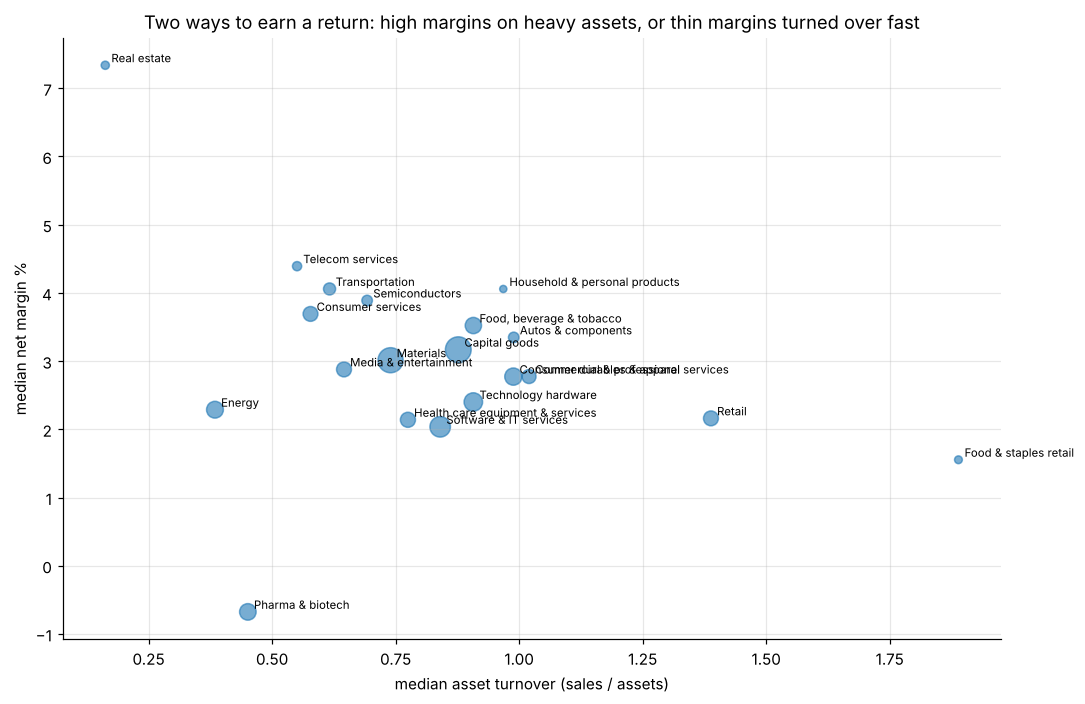

,roe,net_margin,asset_turnover,equity_multiplier,firms
industry,,,,,
Real estate,4.64,7.34,0.16,2.30,726
Energy,4.81,2.29,0.38,1.95,3034
Pharma & biotech,1.78,-0.68,0.45,1.56,2935
Telecom services,7.89,4.39,0.55,2.30,907
Consumer services,5.59,3.69,0.58,1.94,2355
Transportation,7.74,4.06,0.62,2.36,1564
Media & entertainment,5.10,2.88,0.65,1.84,2385
Semiconductors,5.45,3.89,0.69,1.56,1190
Materials,5.94,3.01,0.74,1.95,6735


In [3]:
ind = aggregate.summary(p, "industry", cols)
for c in ["roe", "net_margin", "op_margin", "roa"]: ind[c] *= 100
ind = ind.sort_values("asset_turnover"); ind.to_csv(DATA / "dupont_by_industry.csv")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(ind.asset_turnover, ind.net_margin, s=ind.firms / 25, alpha=0.6, color="C0")
for n, r_ in ind.iterrows(): ax.annotate(n, (r_.asset_turnover, r_.net_margin), fontsize=7.5, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("median asset turnover (sales / assets)"); ax.set_ylabel("median net margin %")
ax.set_title("Two ways to earn a return: high margins on heavy assets, or thin margins turned over fast")
plt.tight_layout(); plt.savefig(IMG / "dupont_industries.png", bbox_inches="tight"); plt.show()
ind[["roe", "net_margin", "asset_turnover", "equity_multiplier", "firms"]].round(2)

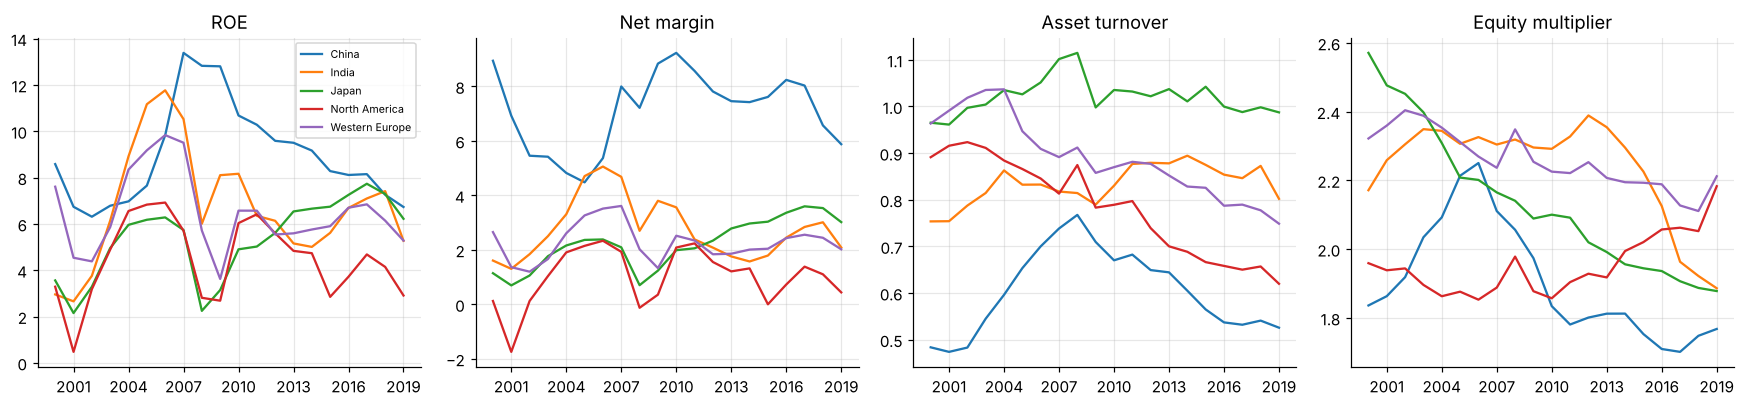

In [4]:
tr = p[p.region.isin(["North America", "Western Europe", "Japan", "China", "India"]) & p.fyear.le(2019)].groupby(["fyear", "region"])[["roe", "net_margin", "asset_turnover", "equity_multiplier"]].median().unstack()
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a, c, t in zip(ax, ["roe", "net_margin", "asset_turnover", "equity_multiplier"], ["ROE", "Net margin", "Asset turnover", "Equity multiplier"]):
    (tr[c] * (100 if c in ["roe", "net_margin"] else 1)).plot(ax=a, legend=a is ax[0]); a.set_title(t); int_years(a)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(IMG / "dupont_trends.png", bbox_inches="tight"); plt.show()

## 2 · Profit persistence
Each firm's operating ROA is measured as its deviation from the median of its country, industry and year. The slope of next year's deviation on this year's gives the share of an abnormal return that survives one year (1 = permanent, 0 = gone). Transition rates show how many top-quintile firms are still in the top quintile three years later.

In [5]:
p["roa_dev"] = p.roa - p.groupby(["loc", "industry_group", "fyear"]).roa.transform("median")
p["roa_dev_next"] = lead("roa_dev", 1)
rows = []
for reg_, d in p.dropna(subset=["roa_dev", "roa_dev_next"]).groupby("region"):
    for sign, s in [("above peers", d.roa_dev > 0), ("below peers", d.roa_dev < 0)]:
        x, y = d.loc[s, "roa_dev"], d.loc[s, "roa_dev_next"]
        rows.append((reg_, sign, np.polyfit(x, y, 1)[0], d.loc[s, "gvkey"].nunique()))
pers = pd.DataFrame(rows, columns=["region", "side", "persistence", "firms"]).pivot(index="region", columns="side", values="persistence").reindex(REG_ORDER)
p["q"] = p.groupby(["loc", "fyear"]).roa.transform(lambda v: pd.qcut(v, 5, labels=False, duplicates="drop") if v.notna().sum() >= 50 else np.nan)
p["q3"] = lead("q", 3)
tq = p[p.q.eq(4) & p.q3.notna()].groupby("region").apply(lambda d: pd.Series({"top quintile still top after 3 years %": 100 * d.q3.eq(4).mean(),
                                                                                "fallen to bottom two quintiles %": 100 * d.q3.le(1).mean()})).reindex(REG_ORDER)
bq = p[p.q.eq(0) & p.q3.notna()].groupby("region").apply(lambda d: pd.Series({"bottom quintile still bottom after 3 years %": 100 * d.q3.eq(0).mean()})).reindex(REG_ORDER)
persist = pers.join(tq).join(bq); persist.to_csv(DATA / "profit_persistence.csv"); persist.round(2)

,above peers,below peers,top quintile still top after 3 years %,fallen to bottom two quintiles %,bottom quintile still bottom after 3 years %
region,,,,,
North America,0.77,0.76,56.73,11.01,67.83
Western Europe,0.72,0.64,55.97,12.14,57.37
Japan,0.79,0.71,55.44,12.58,46.97
Other developed Asia-Pacific,0.70,0.57,49.86,14.96,52.92
China,0.71,0.46,37.88,18.29,54.72
India,0.72,0.45,50.31,12.61,53.45
OIC members,0.76,0.51,51.30,13.99,50.91
Other emerging,0.66,0.52,50.19,15.43,49.53


## 3 · High-growth firms
OECD-Eurostat definition: average sales growth above 20% a year over three years, for firms with at least 10 employees at the start. Growth is in local currency, so high-inflation countries are flagged where relevant. Characteristics are measured in the starting year.

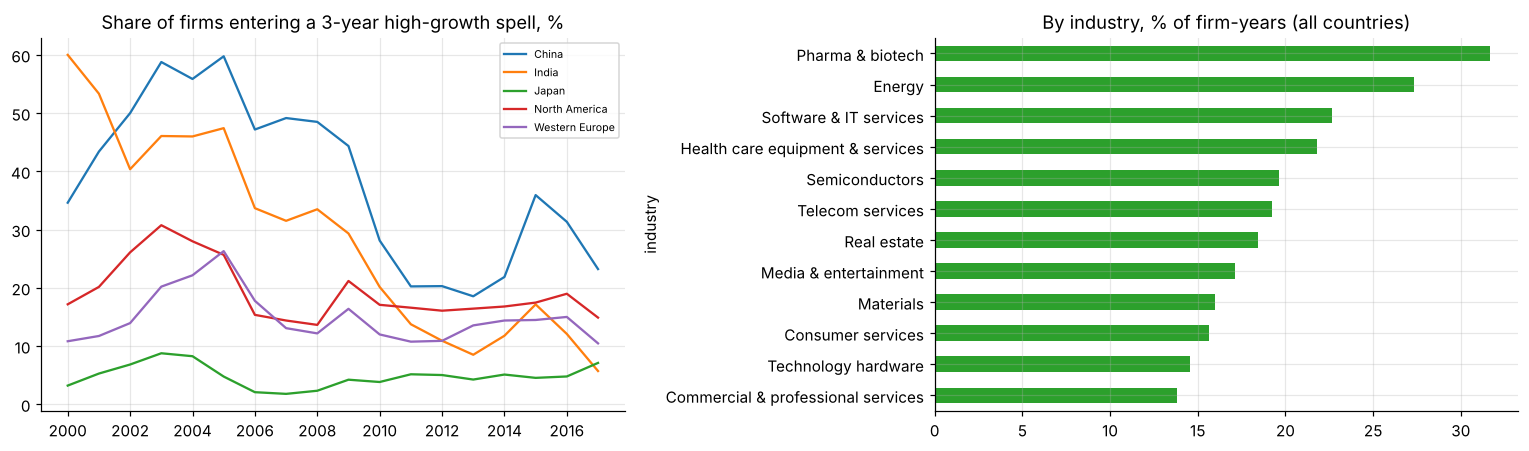

,high_growth,firms,firm_years
region,,,
North America,19.5,8237,65741
Western Europe,14.5,5783,45992
Japan,4.8,3722,44433
Other developed Asia-Pacific,21.5,3699,20928
China,32.1,4083,12182
India,21.8,2423,13203
OIC members,19.9,2408,13700
Other emerging,16.8,2582,14303


In [6]:
s3 = lead("x_sale", 3)
p["cagr3"] = (s3 / p.x_sale) ** (1 / 3) - 1
ok = p.x_emp.ge(0.01) & p.cagr3.notna() & p.x_sale.gt(0)      # Compustat reports employees in thousands
p["high_growth"] = (p.cagr3 > 0.20).astype(float).where(ok)
hg = aggregate.summary(p[ok], "region", ["high_growth"], stat="mean").reindex(REG_ORDER); hg["high_growth"] *= 100
hgi = aggregate.summary(p[ok], "industry", ["high_growth"], stat="mean").sort_values("high_growth", ascending=False); hgi["high_growth"] *= 100
hgy = p[ok & p.region.isin(["North America", "Western Europe", "Japan", "China", "India"])].groupby(["fyear", "region"]).high_growth.mean().unstack() * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
hgy.plot(ax=ax[0]); ax[0].set_title("Share of firms entering a 3-year high-growth spell, %"); int_years(ax[0]); ax[0].legend(fontsize=7)
hgi.high_growth.head(12)[::-1].plot.barh(ax=ax[1], color="C2"); ax[1].set_title("By industry, % of firm-years (all countries)")
plt.tight_layout(); plt.savefig(IMG / "high_growth_firms.png", bbox_inches="tight"); plt.show()
hg.round(1)

In [7]:
traits = ["size", "age", "rd", "intangibles", "cash", "leverage", "roa", "sales_growth", "tangibility"]
cmp_ = p[ok].groupby(["region", "high_growth"])[traits].median().unstack()
diff = pd.DataFrame({t: cmp_[t][1.0] - cmp_[t][0.0] for t in traits}).reindex(REG_ORDER)
pooled = p[ok].groupby("high_growth")[traits].median().T.rename(columns={0.0: "other firms", 1.0: "future high-growth firms"})
pooled.to_csv(DATA / "high_growth_traits.csv")
pd.set_option("display.float_format", "{:.3f}".format)
display(pooled); display(diff.rename(columns=lambda c: c + " (HG − other)"))
pd.reset_option("display.float_format")

high_growth,other firms,future high-growth firms
size,5.671,4.826
age,2.079,1.609
rd,0.000,0.000
intangibles,0.023,0.023
cash,0.109,0.152
leverage,0.191,0.154
roa,0.056,0.041
sales_growth,0.050,0.165
tangibility,0.241,0.179


,size (HG − other),age (HG − other),rd (HG − other),intangibles (HG − other),cash (HG − other),leverage (HG − other),roa (HG − other),sales_growth (HG − other),tangibility (HG − other)
region,,,,,,,,,
North America,-1.088,-0.560,0.005,-0.047,0.098,-0.063,-0.053,0.128,-0.055
Western Europe,-1.312,-0.470,0.000,-0.013,0.061,-0.079,-0.027,0.108,-0.080
Japan,-1.132,-0.470,-0.004,0.009,0.104,-0.020,0.007,0.080,-0.139
Other developed Asia-Pacific,-0.468,-0.405,0.000,-0.001,0.017,-0.025,-0.026,0.083,-0.050
China,-0.260,-0.405,0.009,0.002,0.018,-0.019,0.007,0.096,-0.009
India,-0.314,-0.452,0.000,-0.001,0.004,0.025,0.003,0.087,-0.013
OIC members,-0.132,-0.336,0.000,-0.000,0.003,0.021,-0.011,0.037,-0.005
Other emerging,-0.121,-0.470,0.000,-0.000,0.015,0.006,0.000,0.078,-0.033


## 4 · Productivity: sales and operating profit per employee
In USD thousands per employee (2019, the last full year), for firms reporting employees.

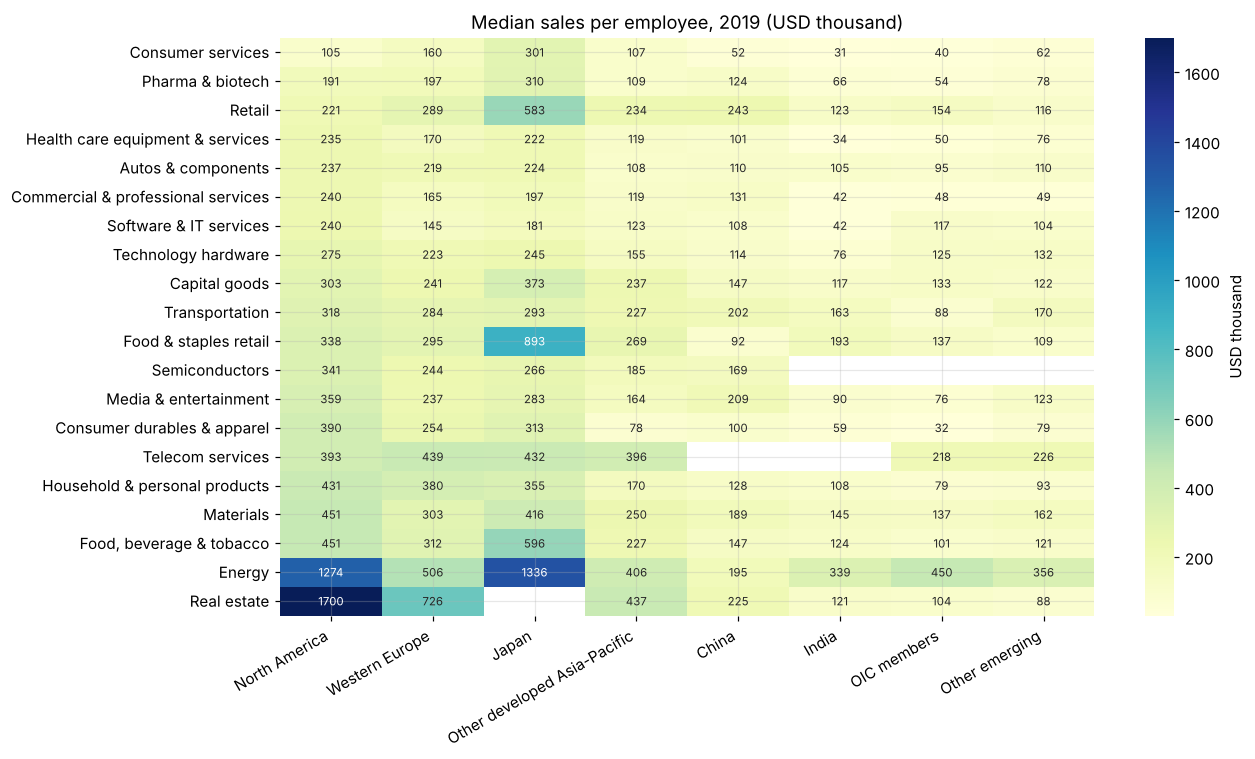

In [8]:
e = p.x_emp.where(p.x_emp >= 0.01) * 1000
p["sales_per_emp"] = wins(p.x_sale / p.x_lcu_per_usd / e * 1000)        # USD thousands per employee
p["op_profit_per_emp"] = wins(p.x_oiadp / p.x_lcu_per_usd / e * 1000)
y19 = p[p.fyear.eq(2019)]
prod = aggregate.summary(y19, ["industry", "region"], ["sales_per_emp"]).sales_per_emp.unstack()[REG_ORDER]
prod = prod.loc[prod.notna().sum(axis=1).sort_values(ascending=False).index]
prod.to_csv(DATA / "sales_per_employee_2019.csv")
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(prod.sort_values("North America"), annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "USD thousand"}, annot_kws={"size": 7.5})
ax.set_title("Median sales per employee, 2019 (USD thousand)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.savefig(IMG / "sales_per_employee.png", bbox_inches="tight"); plt.show()

In [9]:
ctry = aggregate.summary(y19, "loc", ["sales_per_emp", "op_profit_per_emp", "gdp_pc"], min_firms=50).sort_values("sales_per_emp", ascending=False)
ctry.to_csv(DATA / "productivity_by_country_2019.csv")
rho = ctry[["sales_per_emp", "gdp_pc"]].dropna().corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation of median sales per employee with GDP per capita across {len(ctry)} countries: {rho:.2f}")
ctry.round(1).head(15)

Spearman correlation of median sales per employee with GDP per capita across 51 countries: 0.70


,sales_per_emp,op_profit_per_emp,gdp_pc,firms,firm_years
loc,,,,,
KOR,444.5,46.8,33496.3,1529,1529
NOR,371.1,13.4,79937.5,153,153
JPN,326.2,16.3,36837.3,2927,2927
USA,313.5,13.5,61048.0,3459,3459
ITA,309.6,21.1,32180.4,264,264
CAN,296.6,10.9,45100.3,812,812
IRL,283.2,24.4,76485.6,66,66
NZL,280.2,20.9,40615.7,106,106
NLD,278.9,13.8,49254.0,104,104


## Findings
* **Return on equity is driven by margins in emerging markets and by debt and turnover in rich ones.** Median ROE (2000-2020) ranges from 4.5% in North America to 8.7% in China and other emerging markets. Chinese firms earn the highest net margins (7.2%) but turn their assets over most slowly (0.60x). North American firms have the thinnest median margin (1.0%), dragged down by many loss-making small caps.
* **Industries take one of two routes to a return:** high margins on heavy assets (real estate 7.3% margin at 0.16x turnover, telecoms, transport) or thin margins turned over fast (food retail 1.6% at 1.9x, retail 2.2% at 1.4x). The biggest gap is in pharma and biotech: median net margin is negative (-0.7%) because of loss-making development-stage firms.
* **Asset turnover has been falling almost everywhere since the mid-2000s.** It fell from about 0.9 to 0.55 in North America and from 0.97 to 0.7 in Western Europe, while Japan held near 1.0. China fell from 0.77 (2008) to 0.52 (2019). Firms hold more assets, mostly intangibles and cash, for each dollar of sales.
* **Abnormal profits persist longest in developed markets.** In North America and Japan, 77-79% of a firm's above-peer ROA survives into the next year, and 57% of top-quintile firms are still top-quintile three years later. In China only 38% stay on top. Losses are stickiest in North America: 68% of bottom-quintile firms are still there three years later, against 47% in Japan.
* **High-growth firms (20%+ a year for three years) are common in China (32% of firm-years) and rare in Japan (5%).** North America (20%) and Western Europe (15%) sit in between. Future high-growth firms start out smaller, younger, more cash-rich and less leveraged, with lower current ROA and lower tangibility. Pharma, energy and software produce the most growth spells.
* **Productivity rises with national income** (rank correlation 0.70 between median sales per employee and GDP per capita across 51 countries). In 2019 the median firm sold USD 445k per employee in Korea, 326k in Japan and 314k in the USA. Within industries, Japanese retailers and food retailers stand out (USD 583k and 893k), reflecting thin-margin, high-volume trading models.